# Topic 2 -- Data Processing

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**Topic Learning Objectives**:
1. Manipulate data with NumPy
2. Use indices to extract sub-tables
3. Use NumPy functionality to obtain statistical information from datasets
4. Perform basic Linear Algebra operations involving vectors and matrices
5. Evaluate determinants, ranks and traces of matrices
6. Use the pandas library to manipulate datasets
7. 
Process and visualise time series data

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 2.2 Data Manipulation with Pandas </h2>
</div>

### 2.2.1 Pandas Series and DataFrame

#### Pandas: Python Data Analysis Library

- Provides data structures and tools for analysis
- Open source
- Very wide used in academia and industry
- Integrates with other packages to enable a complete analysis workflow
    * NumPy
    * SciPy
    * Matplotlib
    * scikit-learn (or sklearn)

#### Core Data Structures

- Series
    * One-dimensional labelled array
    * Data can be any type
- DataFrame
    * Two-dimensional labelled table
    * Columns can be of different types

In [1]:
# Install Pandas (if necessary)
#!pip install pandas  

In [2]:
import pandas as pd
pd.__version__

'2.2.2'

#### Pandas Series

In [3]:
# Create a Pandas Series
s = pd.Series([1,2,3], ['a','b','c'], name='data')
#s = pd.Series([1,2,3], ['a','b','c'])
s

a    1
b    2
c    3
Name: data, dtype: int64

In [4]:
### Insert code to access elements in the Pandas Series

In [5]:
s.index

Index(['a', 'b', 'c'], dtype='object')

In [6]:
s.index.dtype

dtype('O')

In [7]:
s[['a','c']]

a    1
c    3
Name: data, dtype: int64

In [8]:
s.loc[['a','c']]

a    1
c    3
Name: data, dtype: int64

In [9]:
s.iloc[0:2]

a    1
b    2
Name: data, dtype: int64

In [10]:
# Boolean indexing
s[s > 1] 

b    2
c    3
Name: data, dtype: int64

In [11]:
s * 3

a    3
b    6
c    9
Name: data, dtype: int64

#### Pandas DataFrame

In [12]:
# Create a dataframe using a list (or list of lists)
pd.DataFrame([
    [1, 'a'],
    [2, 'b'],
    [3, 'c']], 
    columns=['col1', 'col2'])

,col1,col2
0,1,a
1,2,b
2,3,c


In [13]:
# Create a dataframe using a dictionary
data = {
    'col1': [1, 2, 3],
    'col2': ['a', 'b', 'c']
}
pd.DataFrame(data)

,col1,col2
0,1,a
1,2,b
2,3,c


In [14]:
# Create some data on student enrolment - with some missing values
# Save data to a file named "class_data.csv"

import pandas as pd
import numpy as np
import os

np.random.seed(101)

# Data pools
gender = ['male', 'female']
programmes = ['Computer Science', 'Statistics', 'Engineering']

# Function to randomly introduce missing values
def introduce_missing(data_list, missing_rate=0.1):
    return [val if np.random.random() > missing_rate else np.nan for val in data_list]


# Number of samples
num_samples = 100

# Set mean and standard deviation for height (e.g., mean = 170 cm, std = 10 cm)
mean_height = 170  # mean height in cm
std_dev_height = 10  # standard deviation in cm

# Generate the data
data = {
    "gender": introduce_missing([np.random.choice(gender) for _ in range(num_samples)]),
    "height": introduce_missing([int(np.random.normal(mean_height, std_dev_height)) for _ in range(num_samples)]),
    "programme": introduce_missing([np.random.choice(programmes) for _ in range(num_samples)]),
}

# Create DataFrame
df = pd.DataFrame(data)

# Save to CSV
if not os.path.exists("class_data.csv"):
    df.to_csv("class_data.csv", index=False)
    print("File saved.")
else:
    print("File exists. Not saved.")

# Preview the data
print(df.head())   

File exists. Not saved.
   gender  height         programme
0  female     NaN  Computer Science
1  female   162.0       Engineering
2     NaN     NaN       Engineering
3    male   153.0       Engineering
4  female   176.0       Engineering


In [15]:
### Insert code to try out some basic functions in the Pandas DataFrame

In [16]:
### Insert code to access elements in the Pandas DataFrame

In [19]:
df = pd.read_csv("class_data.csv")
df.head()

,gender,height,programme
0,female,NaN,Computer Science
1,female,162.0,Engineering
2,NaN,NaN,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering


In [21]:
df.sample(5)

,gender,height,programme
89,male,179.0,Engineering
18,NaN,167.0,Engineering
61,male,159.0,Statistics
27,male,165.0,Computer Science
78,female,170.0,Engineering


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   gender     91 non-null     object 
 1   height     91 non-null     float64
 2   programme  92 non-null     object 
dtypes: float64(1), object(2)
memory usage: 2.5+ KB


In [23]:
df.isna().sum()

gender       9
height       9
programme    8
dtype: int64

In [25]:
df['gender'] = df['gender'].astype('category')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   gender     91 non-null     category
 1   height     91 non-null     float64 
 2   programme  92 non-null     object  
dtypes: category(1), float64(1), object(1)
memory usage: 1.9+ KB


In [26]:
df.gender.dtype

CategoricalDtype(categories=['female', 'male'], ordered=False, categories_dtype=object)

In [27]:
df.describe()  

,height
count,91.000000
mean,169.637363
std,10.573044
min,142.000000
25%,162.000000
50%,170.000000
75%,176.000000
max,194.000000


In [29]:
df.describe(include='all')

,gender,height,programme
count,91,91.000000,92
unique,2,NaN,3
top,female,NaN,Engineering
freq,49,NaN,41
mean,NaN,169.637363,NaN
std,NaN,10.573044,NaN
min,NaN,142.000000,NaN
25%,NaN,162.000000,NaN
50%,NaN,170.000000,NaN
75%,NaN,176.000000,NaN


In [31]:
df['gender']

0     female
1     female
2        NaN
3       male
4     female
       ...  
95    female
96      male
97      male
98      male
99      male
Name: gender, Length: 100, dtype: category
Categories (2, object): ['female', 'male']

In [30]:
type(df['gender'])

pandas.core.series.Series

In [32]:
type(df[['gender']])

pandas.core.frame.DataFrame

In [34]:
df.loc[0]

gender                 female
height                    NaN
programme    Computer Science
Name: 0, dtype: object

In [35]:
df.loc[0:5]

,gender,height,programme
0,female,NaN,Computer Science
1,female,162.0,Engineering
2,NaN,NaN,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering
5,female,170.0,Computer Science


In [39]:
df.loc[[0,2,5]]

,gender,height,programme
0,female,NaN,Computer Science
2,NaN,NaN,Engineering
5,female,170.0,Computer Science


In [36]:
df.iloc[0:5]

,gender,height,programme
0,female,NaN,Computer Science
1,female,162.0,Engineering
2,NaN,NaN,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering


In [ ]:
df['height'] > 160

0     False
1      True
2     False
3     False
4      True
      ...  
95     True
96     True
97    False
98     True
99     True
Name: height, Length: 100, dtype: bool

In [41]:
df[df['height'] > 160]

,gender,height,programme
1,female,162.0,Engineering
4,female,176.0,Engineering
5,female,170.0,Computer Science
9,female,191.0,NaN
10,female,171.0,Engineering
...,...,...,...
94,male,182.0,Computer Science
95,female,165.0,Engineering
96,male,172.0,Statistics
98,male,179.0,Engineering


In [ ]:
# Working with missing values

In [42]:
df.isna().sum()

gender       9
height       9
programme    8
dtype: int64

In [43]:
df.isnull().sum()

gender       9
height       9
programme    8
dtype: int64

In [ ]:
# Working with time series

In [44]:
df.head(5)

,gender,height,programme
0,female,NaN,Computer Science
1,female,162.0,Engineering
2,NaN,NaN,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering


In [45]:
df.ffill()

,gender,height,programme
0,female,NaN,Computer Science
1,female,162.0,Engineering
2,female,162.0,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering
...,...,...,...
95,female,165.0,Engineering
96,male,172.0,Statistics
97,male,172.0,Engineering
98,male,179.0,Engineering


In [46]:
df.dfill()

AttributeError: 'DataFrame' object has no attribute 'dfill'

In [ ]:
# Only works for numerical data
df.interpolate(method='linear')

C:\Users\User\AppData\Local\Temp\ipykernel_14568\1321276365.py:1: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df.interpolate(method='linear')


NotImplementedError: Categorical does not implement interpolate

In [ ]:
# Does not include height for first row as it is not inbetween 2 values
df['height'].interpolate(method='linear')

0       NaN
1     162.0
2     157.5
3     153.0
4     176.0
      ...  
95    165.0
96    172.0
97    175.5
98    179.0
99    175.0
Name: height, Length: 100, dtype: float64

In [ ]:
# Impute missing values (Non time series)

In [49]:
df['height'].fillna(200)

0     200.0
1     162.0
2     200.0
3     153.0
4     176.0
      ...  
95    165.0
96    172.0
97    200.0
98    179.0
99    175.0
Name: height, Length: 100, dtype: float64

In [ ]:
# More suitable for numerical data
df['height'].fillna(df['height'].mean())

0     169.637363
1     162.000000
2     169.637363
3     153.000000
4     176.000000
         ...    
95    165.000000
96    172.000000
97    169.637363
98    179.000000
99    175.000000
Name: height, Length: 100, dtype: float64

In [ ]:
# More suitable for numerical data
df['height'].fillna(df['height'].median())

0     170.0
1     162.0
2     170.0
3     153.0
4     176.0
      ...  
95    165.0
96    172.0
97    170.0
98    179.0
99    175.0
Name: height, Length: 100, dtype: float64

In [ ]:
# More suitable for categorical data
df['height'].fillna(df['height'].mode())

0     153.0
1     162.0
2     173.0
3     153.0
4     176.0
      ...  
95    165.0
96    172.0
97      NaN
98    179.0
99    175.0
Name: height, Length: 100, dtype: float64

In [ ]:
# Drop rows with missing values

In [53]:
# Drop rows with missing values
df.dropna()

,gender,height,programme
1,female,162.0,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering
5,female,170.0,Computer Science
6,female,153.0,Statistics
...,...,...,...
94,male,182.0,Computer Science
95,female,165.0,Engineering
96,male,172.0,Statistics
98,male,179.0,Engineering


In [54]:
df.dropna(subset=['gender','height'])

,gender,height,programme
1,female,162.0,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering
5,female,170.0,Computer Science
6,female,153.0,Statistics
...,...,...,...
94,male,182.0,Computer Science
95,female,165.0,Engineering
96,male,172.0,Statistics
98,male,179.0,Engineering


### 2.2.2 Time Series

- Change over time
- Line graphs are most common method
- Sequence of variable measurements, indexed by time, e.g., London population
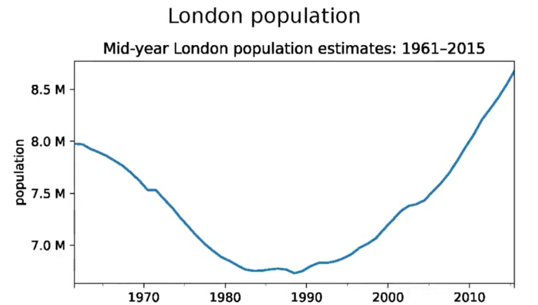

#### Uses and Applications
- Business and finance: Analysis of stock price, costs, profit, unit sold, etc.
- Organisational: Monitoring process or quality, workload projections
- Government and policy making: Changes in economics, health, crime statistics
- Science and engineering: Signal processing, energy efficiency, cell mutation, etc.
- Anything involving measurements over time

#### Looking for Trends
- Seasonal variation
- Significant events: Natural disasters, changes of government, tax regulation, etc.
- Correlations: Do variable change in similar ways over time?
- Understanding the past
- Predicting the future

#### Different Kinds of Patterns
- Variability
- Rate of change
- Co-variance and correlation
- Cycles
- Exceptions

#### Sampling Rate
- Some variables are constantly changing over time, e.g., temperature, physiological response, stock market
- Rate of measurement is important
    * Temperature: one measurement per hour, or one measurement per second?
    * Stock market: trend over a whole year, or changes over milliseconds?
- Depends on application and/or research questions

#### Time-Related Concepts in Pandas
- **Date times**: A specific date and time with timezone support
- **Time deltas**: An absolute time duration
- **Time spans**: A span of time defined by a point in time and its associated frequency
- **Date offsets**: A relative time duration that respects calendar arithmetic

  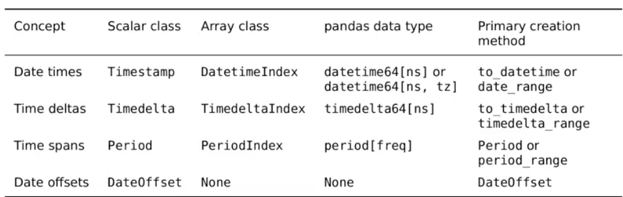

  ###### Source: pandas user guide: time series / date functionality

In [17]:
### Insert code to try out time-related functions

In [60]:
print(pd.Timestamp('2020'))
print(pd.Timestamp('2020-01-02'))
print(pd.Timestamp('2020-02-02, 09:30'))

2020-01-01 00:00:00
2020-01-02 00:00:00
2020-02-02 09:30:00


In [56]:
type(pd.Timestamp('2020'))

pandas._libs.tslibs.timestamps.Timestamp

In [62]:
pd.to_datetime('11/12/2020', dayfirst=True)

Timestamp('2020-12-11 00:00:00')

In [ ]:
# Generate sequences of timestamps

In [63]:
pd.to_datetime(['2020-01-01','2020-01-02','2020-01-03'])

DatetimeIndex(['2020-01-01', '2020-01-02', '2020-01-03'], dtype='datetime64[ns]', freq=None)

In [64]:
index = pd.to_datetime(['2020-01-01','2020-01-02','2020-01-03'])
index.inferred_freq

'D'

In [66]:
index = pd.to_datetime(['2020-01-01','2020-02-01','2020-03-01'])
index.inferred_freq

'MS'

### 2.2.3 Time Series Analysis

#### Time Series Analysis - Summing Variables

Download dataset (xlsx file) from London Datastore -- https://data.london.gov.uk/dataset/historic-census-population.  Then rename file to 'population.xlsx'

Alternatively, you can load the Excel (xlsx) file directly from 'https://data.london.gov.uk/download/227f750f-69ab-4605-8e30-1f0ca6744527/2c7867e5-3682-4fdd-8b9d-c63e289b92a6/population%201801%20to%202021.xlsx'


In [18]:
import pandas as pd

# Load the downloaded and renamed dataset
df = pd.read_excel('population.xlsx', sheet_name='data', header=0, skiprows=range(1,35), nrows=3)

# Load the dataset directly from the website
# url = 'https://data.london.gov.uk/download/227f750f-69ab-4605-8e30-1f0ca6744527/2c7867e5-3682-4fdd-8b9d-c63e289b92a6/population%201801%20to%202021.xlsx'
# df = pd.read_excel(url, sheet_name='data', header=0, skiprows=range(1,35), nrows=3)

# Set 'area' as index
df.set_index('area', inplace=True)

# Sum the populations for Central London and Rest of Inner London for each year
inner_london = df.loc['Central London'] + df.loc['Rest of Inner London']

# Add the combined data back into the DataFrame as 'inner'
df.loc['inner'] = inner_london

# Rename 'Outer London' to 'outer'
df.rename(index={'Outer London': 'outer'}, inplace=True)

# Keep only 'inner' and 'outer' rows
df = df.loc[['inner', 'outer']]

# Display the filtered DataFrame
df

FileNotFoundError: [Errno 2] No such file or directory: 'population.xlsx'

In [ ]:
# Melt the DataFrame: Converts the years into a single column and each area as its own value
df_melted = df.reset_index().melt(id_vars='area', var_name='year', value_name='population')
print(df_melted.head(),'\n')

# Now, pivot the DataFrame: 'year' as index and 'area' as columns
df_pivoted = df_melted.pivot(index='year', columns='area', values='population')
print(df_pivoted.head())


In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Create the plot
plt.figure(figsize=(10, 5))

# Plot each area's line
for area in df_pivoted.columns:
    plt.plot(df_pivoted.index, df_pivoted[area], label=area)

# Plot the total of 'inner' and 'outer'
plt.plot(
    df_pivoted.index,
    df_pivoted['inner'] + df_pivoted['outer'],
    label='total',
    color='black',
    linestyle='--'
)

# Add labels, title, and legend
plt.title('Population by Area Over Time')
plt.xlabel('Year')
plt.ylabel('Population')
plt.legend()

# Format y-axis to avoid scientific notation (e.g., use "1M" instead of "1e6")
plt.gca().yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=2))

# Final layout and display
plt.tight_layout()
plt.show()


#### Time Series Analysis - Difference Between Variables

In [ ]:
# Set multi-level index
df_melted.set_index(['year', 'area'], inplace=True)
df_melted.head()

In [ ]:
# Calculate difference between variables
difference = (df_melted.xs('outer', level='area') -
              df_melted.xs('inner', level='area'))
difference.name = 'difference'
difference.head()

In [ ]:
plt.figure(figsize=(10, 5)) 

# Plot the difference (outer - inner)
plt.plot(difference.index, 
         difference, 
         label='Difference (Outer - Inner)', 
         linestyle='--', 
         color='red')

# Add title and labels
plt.title('Difference Between Outer and Inner Population Over Time')
plt.xlabel('Year')
plt.ylabel('Population Difference')
plt.gca().yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=2))

# Add legend
plt.legend()

# Disable gridlines if not needed
plt.grid(False)

# Ensure the layout is tight and show the plot
plt.tight_layout()
plt.show()

In [ ]:
# Find the maximum difference value
difference.max()

In [ ]:
# Find the year in which the difference was biggest
max_year = difference.idxmax()
max_year

In [ ]:
df_melted.loc[max_year]

In [ ]:
# Slice data from 1981 to 2021
ax = difference.loc['1981':].plot()
ax.set_title('''Difference between the populations of outer and inner London: 1981-2021''')
ax.yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=2))
plt.show()

In [ ]:
# Year-on-year change
# diff() method calculates change between observations

# ax = df_melted.unstack('area').diff().plot()
ax = df_melted.unstack('area').diff().loc['1981':].plot()
ax.set_title('''Change in the populations of inner and outer London''')
ax.yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=1))
ax.set_ylabel('population')
ax.legend(title="Population Change")
plt.show()

#### Time Series Analysis - Rolling Correlation

In [ ]:
# Rolling correlation between inner and outer London

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)

# Change on top plot
ax1 = df_melted.unstack('area').diff().plot(ax=ax1)
ax1.yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=1))
ax1.set_title('Change in the populations of inner and other London')
ax1.set_ylabel('population')
ax1.legend(title=None)

# Correlation on bottom plot
# Create windowed correlation between inner and outer
c = df_pivoted.loc[:, 'inner'].rolling(window=3).corr(df_pivoted.loc[:, 'outer'])
# Plot the relationship
c.plot(ax=ax2)

# Adjust y-axis range
ax2.set_ylim(-1.1, 1.1)
ax2.set_title('''Rolling correlation over 3 period window between population of inner and outer London''')
ax2.set_ylabel('correlation')
fig.subplots_adjust(hspace=0.5)
plt.show()

#### Time Series Analysis - Testing for Randomness

In [ ]:
# Testing for randomness
import numpy as np

ax = pd.Series(np.random.rand(1000)).plot()
ax.set_title('Random data')
plt.show()

In [ ]:
# Testing for randomness: Lag plot of random data
from pandas.plotting import lag_plot

ax = lag_plot(pd.Series(np.random.rand(1000)))
# ax = lag_plot(pd.Series(np.random.rand(1000)), lag=2)  # Default lag=1
ax.set_title('Lag plot of random data')
plt.show()

In [ ]:
# Testing for randomness: Lag plot of inner London population
from pandas.plotting import lag_plot

ax = lag_plot(df_pivoted.loc[:, 'inner'])
ax.set_title('Lag plot of inner London population')
ax.xaxis.set_major_formatter(mpl.ticker.EngFormatter(places=1))
ax.yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=1))
plt.show()

In [ ]:
# Testing for randomness: Autocorrelation plot of inner London population
from pandas.plotting import autocorrelation_plot

ax = autocorrelation_plot(df_pivoted.loc[:, 'inner']) 
ax.set_title('Autocorrelation plot of inner London population')
plt.show()

In [ ]:
# Testing for randomness: Autocorrelation plot of random data
from pandas.plotting import autocorrelation_plot

ax = autocorrelation_plot(pd.Series(np.random.rand(1000))) 
ax.set_title('Autocorrelation plot of random data')
plt.show()